# Tutorial 3: Analyze SeqFISH mouse embryo dataset
Mouse Olfactory Bulb

In this tutorial, we demonstrate how to apply Redex to  mouse embryo seqFISH dataset.

The data should be placed under  './SEQFISH'.

## Loading packages

In [ ]:
# Installed package imports
import os
import scanpy as sc
import pandas as pd
import method
import Redex
import matplotlib.pyplot as plt
from utils import clustering, evaluate, plot_spatial, plot_umap, plot_paga

os.environ['R_HOME'] = '/home/user/anaconda3/envs/redex/lib/R'

## Configuration

In [2]:
DATA_ROOT   = './SEQFISH'
RESULT_ROOT = './results'
FIG_ROOT    = './figures/seqfish'
DATASETS = {
    'SEQFISH': {'n_clusters': 24, 'embryo': 1},
}

## Load data and Helper functions
To read the seqfish data and plot all its regions, additional functions are required.

In [ ]:

def load_seqfish(data_path, embryo=1):
    counts   = pd.read_csv(os.path.join(data_path, "counts.txt"),   sep="\t")
    metadata = pd.read_csv(os.path.join(data_path, "metadata.txt"), sep="\t")

    metadata = metadata[metadata["embryo"] == f"embryo{embryo}"]
    counts   = counts.loc[:, metadata["uniqueID"]]

    spatial = metadata[["x_global", "y_global"]]
    spatial.index = metadata["uniqueID"]

    adata = sc.AnnData(counts.T)
    adata.var_names_make_unique()
    adata.obsm["spatial"] = spatial.to_numpy()

    annotation = metadata["celltype_mapped_refined"]
    annotation.index = metadata["uniqueID"]
    adata.obs["annotation"] = annotation

    return adata

# ============================================================
#  Helper: per-domain spatial highlight
# ============================================================

def plot_domain_highlights(adata, save_dir, dataset, spot_size=4):
    unique_domains = np.sort(adata.obs['mclust'].unique().astype(int))
    n_domains = len(unique_domains)
    norm = matplotlib.colors.Normalize(vmin=0, vmax=n_domains - 1)
    scalar_map = plt.cm.ScalarMappable(norm=norm, cmap='turbo')

    out_dir = os.path.join(save_dir, f"{dataset}_individual_mclust")
    os.makedirs(out_dir, exist_ok=True)

    for idx, domain in enumerate(unique_domains):
        adata.obs['highlight'] = (adata.obs['mclust'].astype(int) == domain).astype(str)
        color = scalar_map.to_rgba(idx)

        fig, ax = plt.subplots(figsize=(3, 3), dpi=300)
        sc.pl.spatial(adata, img_key="hires", color='highlight',
                      palette={'True': color, 'False': '#D3D3D3'},
                      title='', spot_size=spot_size, ax=ax,
                      show=False, frameon=False, legend_loc=None)
        ax.axis('off')
        plt.savefig(os.path.join(out_dir, f"domain_{domain:02d}.pdf"), bbox_inches='tight')
        plt.close()
        del adata.obs['highlight']
        

## Step 1: Gene Selection (Skip if the gene set already exists.)
Redex performs SVF selection module by computing the R_g score across multiple expression thresholds (25th, 50th, 75th percentiles) and merging the results.
Since this dataset has only 351 genes, we still apply the Redex SVF module to rank and score the genes.

In [4]:
for dataset in DATASETS:
    save_dir = os.path.join(RESULT_ROOT, dataset)
    gene_result_file = os.path.join(save_dir, 'three_top_rg-results_df.csv')

    if os.path.exists(gene_result_file):
        print(f"[Skip] Gene selection for {dataset} — {gene_result_file} already exists.")
        continue

    print(f"\n{'='*50}")
    print(f"Gene selection for {dataset}")
    print(f"{'='*50}")

    data_path = os.path.join(DATA_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)

    cfg = DATASETS[dataset]
    adata = load_seqfish(data_path, embryo=cfg['embryo'])
    adata = method.preprocess_adata(adata, min_cells=20)
    neighbors = method.compute_neighbors(adata, k_neighbors=6)

    results_dict = {}
    for thre in [25, 50, 75]:
        gene_groups = method.compute_gene_groups(adata, exp_thre=thre, num_workers=1)
        W_gs = method.compute_weight_matrices(adata, neighbors, num_workers=1)
        results, R_g_values = method.compute_r_values(adata, W_gs, num_workers=1)
        results_dict[thre] = results

    results_df = method.merge_files_and_compute_max(results_dict)
    results_df.to_csv(os.path.join(save_dir, 'three_top_rg-results_df.csv'), index=False)
    print(f"Gene selection results saved to {save_dir}")




Gene selection for SEQFISH


Computing gene groups: 100%|███████████████████████████████████████████████████████| 351/351 [00:00<00:00, 1495.36it/s]
D:\Users\jtyu\新建文件夹\NEW MODEL WITH NEW GENE COMBINE\github test\method.py:98: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['L_g'] = adata.var.index.map(lambda x: results[x]['L_g'] if x in results else [])
Computing R values: 100%|████████████████████████████████████████████████████████████| 351/351 [00:05<00:00, 60.50it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|████████████████████████████████████████████████████████████| 351/351 [00:05<00:00, 61.52it/s]


 R_g =A_g * B_g * C_g 


Computing R values: 100%|████████████████████████████████████████████████████████████| 351/351 [00:05<00:00, 62.83it/s]

 R_g =A_g * B_g * C_g 
Gene selection results saved to ./results\SEQFISH


## Step 2: Model Training
After gene selection, we train the Redex model using the selected spatially variable genes.


In [5]:
for dataset, cfg in DATASETS.items():
    n_clusters = cfg['n_clusters']
    embryo     = cfg['embryo']

    print(f"\n{'='*50}")
    print(f"Processing {dataset} (n_clusters={n_clusters})")
    print(f"{'='*50}")

    data_path = os.path.join(DATA_ROOT, dataset)
    gene_path = os.path.join(RESULT_ROOT, dataset)
    save_dir  = os.path.join(RESULT_ROOT, dataset)
    os.makedirs(save_dir, exist_ok=True)

    # ------ Load data ------
    adata = load_seqfish(data_path, embryo=embryo)

    # ------ Train model ------
    model = Redex.Redex(adata, dataset, gene_path)
    adata = model.train()
    


Processing SEQFISH (n_clusters=24)
 self.num_heads 20
 self.alpha 40
 self.self.beta 1
processed SEQFISH our gene 3000
Begin to train ST data...


100%|████████████████████████████████████████████████████████████████████████████████| 600/600 [03:08<00:00,  3.18it/s]

Optimization finished for ST data!


## Step 3: Spatial Clustering
After model training, we apply mclust for spatial clustering with domain refinement.

In [6]:
clustering(adata, n_clusters, radius=5, method='mclust', refinement=True)


R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.0.0
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


## Step 4: Evaluation
We evaluate the clustering performance using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI) against the manual annotation.


In [7]:
from sklearn.metrics import normalized_mutual_info_score
from sklearn import metrics
ari = metrics.adjusted_rand_score(adata.obs['annotation'], adata.obs['mclust'])
nmi = normalized_mutual_info_score(adata.obs['annotation'], adata.obs['mclust'])
print(f"ARI: {ari:.4f}  |  NMI: {nmi:.4f}")


ARI: 0.3697  |  NMI: 0.5662


## Step 5: Visualization
Spatial domain plot

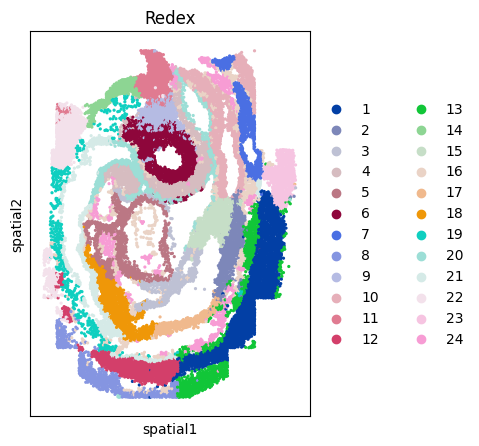

D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
D:\Users\jtyu\software\Anaconda\envs\GraphST\lib\site-packages\scanpy\plotting\_tools\scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


Saved: ./results\SEQFISH\SEQFISH_umap.pdf


<Figure size 300x300 with 0 Axes>

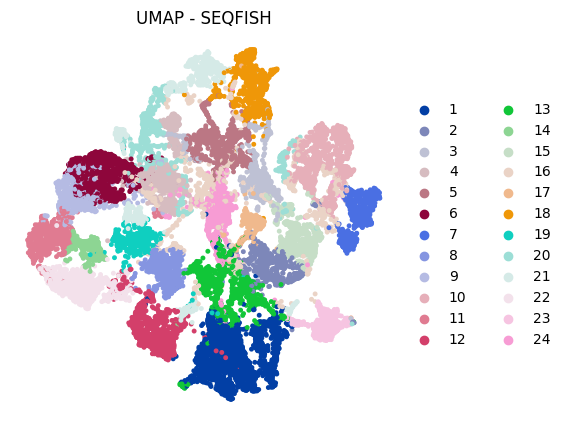

Saved: ./results\SEQFISH\SEQFISH_paga.pdf


<Figure size 300x300 with 0 Axes>

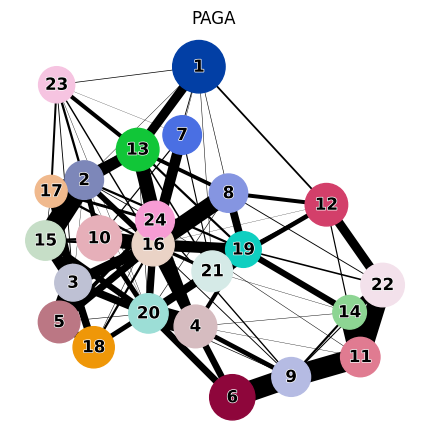

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors
plot_domain_highlights(adata, save_dir, dataset, spot_size=4)

    # ------ Spatial overview ------
plt.rcParams["figure.figsize"] = (5, 5)
sc.pl.spatial(adata, color='mclust', title='Redex', spot_size=2,
                  save=f'{dataset}_Redex.pdf')

    # ------ Embedding plot ------
plt.rcParams["figure.figsize"] = (5, 5)
ax = sc.pl.embedding(adata, basis="spatial", color='mclust',
                         size=7, s=6, show=False, title='Redex')
ax.invert_yaxis()
plt.axis('off')
os.makedirs(FIG_ROOT, exist_ok=True)
plt.savefig(os.path.join(FIG_ROOT, f"{dataset}_embedding.pdf"), dpi=600, bbox_inches='tight')
plt.close()

    # ------ UMAP & PAGA ------
plot_umap(adata, 'mclust',
              title=f'UMAP - {dataset}',
              save_path=os.path.join(save_dir, f'{dataset}_umap.pdf'))

plot_paga(adata, 'mclust',
              save_path=os.path.join(save_dir, f'{dataset}_paga.pdf'))


## Step 6: Find marker gene
Find marker gene for each domain 

In [9]:
from utils import find_marker_genes
marker_dir = './results/SEQFISH/marker'
find_marker_genes(adata, marker_dir, quant_in=30, quant_out=70)
print(f"Dataset {dataset} done.")
    

Marker genes saved to ./results/SEQFISH/marker
Dataset SEQFISH done.
